# Percent of opening EV versus return differences

Compare **close1 minus open** and **close2 minus open**, using the **opening inference model** for both markets. All saved validation and test events are included; no flat/trend filters or added stake multipliers. Original opening no-decay and closing decay sizing is retained, so this is a strategy comparison, not an isolated odds-change experiment.

Percent EV means expected event profit as a percentage of starting bankroll: `100 * sum(stake fraction * EV per unit stake)`, including moneylines and each parlay ticket once. Closing EV is reconstructed from saved model probabilities and market prices; ticket EV assumes independent leg outcomes, matching the portfolio convention. Realized return includes moneylines and parlays. The x-axis is **100 * closing event EV / opening event EV**: 100% means the same EV as opening, 50% means half. The y-axis remains **closing minus opening realized return**, in percentage points. Zero opening EV makes the ratio undefined and is explicitly reported and excluded from correlation plots only; negative opening EV is retained but makes the ratio harder to interpret. Pearson and Spearman correlations and fitted lines are descriptive.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/ufc_betting').is_dir())
if str(ROOT/'src') not in sys.path: sys.path.insert(0,str(ROOT/'src'))
from ufc_betting.config import settings
BACKTESTS=settings.data_dir/'backtest_results/model_comparisons/inference_market_models'

def load_events(prefix,market):
    stem=f'{prefix}_open_with_{market}_inference_{"no_decay" if market=="open" else "decay"}'
    ml=pd.read_csv(BACKTESTS/f'{stem}_moneylines.csv',parse_dates=['date'])
    pl=pd.read_csv(BACKTESTS/f'{stem}_parlays.csv',parse_dates=['date'])
    for f in (ml,pl): f['date']=f.date.dt.normalize()
    cols=['bankroll_postevent','event_payout_money_line','parlay_net','event_total_fstar']
    assert ml.groupby('date')[cols].nunique(dropna=False).le(1).all().all()
    event=ml.groupby('date')[cols].first().sort_index()
    start=event.bankroll_postevent-event.event_payout_money_line-event.parlay_net
    assert start.gt(0).all()
    np.testing.assert_allclose(start.iloc[1:],event.bankroll_postevent.iloc[:-1],rtol=1e-8,atol=1e-8)
    if 'choice_ev' in ml:
        unit_ev=ml.choice_ev
    else:
        selected_red=ml.pred_winner.eq(1)
        prob=ml.proba_red.where(selected_red,ml.proba_blue)
        price=ml[f'dec_{market}_red'].where(selected_red,ml[f'dec_{market}_blue'])
        unit_ev=prob*price-1
        ml['selected_probability']=prob
        ml['selected_price']=price
    assert np.isfinite(unit_ev).all()
    ml_ev=(ml.choice_fstar*unit_ev).groupby(ml.date).sum()
    ticket_rows=[]
    if 'parlay_strategy' in pl:
        for (date,strategy),g in pl.groupby(['date','parlay_strategy']):
            assert g[['fstar_parlay','parlay_ev','parlay_net_odds']].nunique(dropna=False).le(1).all()
            ticket_rows.append(dict(date=date,stake=g.fstar_parlay.iloc[0],ev=g.parlay_ev.iloc[0],net=g.parlay_net_odds.iloc[0]))
    else:
        # Decay export creates exactly one ticket per event and stores global fight row indices.
        for date,g in pl.groupby('date'):
            assert g[['fstar_parlay','parlay_net_odds']].nunique(dropna=False).le(1).all()
            assert g.fight_index.is_unique
            legs=ml.loc[g.fight_index.to_numpy()].copy()
            assert legs.date.eq(date).all()
            names=legs.fighter_red.where(legs.pred_winner.eq(1),legs.fighter_blue).to_numpy()
            np.testing.assert_array_equal(names,g.choice_fighter_name.to_numpy())
            ticket_rows.append(dict(date=date,stake=g.fstar_parlay.iloc[0],
                ev=np.prod(legs.selected_probability*legs.selected_price)-1,net=g.parlay_net_odds.iloc[0]))
    tickets=pd.DataFrame(ticket_rows)
    def total(values): return values.groupby(tickets.date).sum().reindex(event.index,fill_value=0)
    ticket_ev=total(tickets.stake*tickets.ev)
    np.testing.assert_allclose(total(tickets.stake*tickets.net),event.parlay_net/start,atol=1e-9)
    np.testing.assert_allclose(ml.choice_fstar.groupby(ml.date).sum()+total(tickets.stake),event.event_total_fstar,atol=1e-9)
    result=pd.DataFrame({'ev_pct':100*(ml_ev+ticket_ev),'return_pct':100*(event.event_payout_money_line+event.parlay_net)/start})
    assert result.index.is_unique and np.isfinite(result).all().all()
    return result

parts=[];counts=[]
for split,prefix in [('Validation','train_val'),('Test','trainval_test')]:
    markets={m:load_events(prefix,m) for m in ['open','close1','close2']}
    for market,data in markets.items():
        pd.testing.assert_index_equal(data.index,markets['open'].index)
        counts.append(dict(split=split,market=market,events=len(data)))
    for close in ['close1','close2']:
        frame=markets['open'].join(markets[close],lsuffix='_open',rsuffix='_closing',validate='one_to_one')
        frame['delta_ev_pp']=frame.ev_pct_closing-frame.ev_pct_open
        frame['delta_return_pp']=frame.return_pct_closing-frame.return_pct_open
        frame['pair']=f'{close} - open';frame['split']=split
        parts.append(frame.reset_index())
pairs=pd.concat(parts,ignore_index=True)
assert not pairs.duplicated(['pair','split','date']).any()
print('All saved events matched, with no filtering:')
print(pd.DataFrame(counts).to_string(index=False))

# EV ratio is undefined when opening expected return is exactly zero.
pairs['pct_of_open_ev'] = 100 * pairs.ev_pct_closing / pairs.ev_pct_open.replace(0, np.nan)
ratio_audit = pairs.groupby('pair').agg(events=('date','size'),
    zero_open_ev=('ev_pct_open', lambda x: int(x.eq(0).sum())),
    negative_open_ev=('ev_pct_open', lambda x: int(x.lt(0).sum())))
print('Opening EV denominator audit:')
print(ratio_audit.to_string())
plot_pairs = pairs.loc[np.isfinite(pairs.pct_of_open_ev)].copy()
print(f'Undefined/nonfinite ratio rows excluded from plots: {len(pairs)-len(plot_pairs)}')


All saved events matched, with no filtering:
     split market  events
Validation   open      72
Validation close1      72
Validation close2      72
      Test   open      33
      Test close1      33
      Test close2      33
Opening EV denominator audit:
               events  zero_open_ev  negative_open_ev
pair                                                 
close1 - open     105             1                 0
close2 - open     105             1                 0
Undefined/nonfinite ratio rows excluded from plots: 2


### Pearson correlation uncertainty

Tables include approximate pointwise **95% percentile bootstrap confidence intervals** for Pearson r, using 10,000 paired circular block resamples of 5 consecutive calendar events, separately within validation and test. Combined draws retain the original split sizes. For the <=100% table, resample the original event sequence and then reapply the cutoff in every draw; do not collapse gaps between eligible events. Undefined EV ratios are excluded within each draw. These descriptive intervals assume within-split stability, are not adjusted for multiple comparisons, and do not include model-fitting uncertainty.


In [2]:
# Approximate pointwise 95% intervals; resample original chronological rows,
# then apply the EV cutoff within each draw so filtered gaps are not collapsed.
BOOTSTRAP_DRAWS = 10000
BOOTSTRAP_BLOCK_EVENTS = 5

def pearson_block_ci(pair, split, filtered=False):
    source = pairs.loc[pairs.pair.eq(pair)].copy()
    if split != 'Combined': source = source.loc[source.split.eq(split)]
    rng = np.random.default_rng(20261109)
    sampled = []
    for _, group in source.groupby('split', sort=False):
        group = group.sort_values('date')
        values = group[['pct_of_open_ev','delta_return_pp']].to_numpy()
        n = len(values); block = min(BOOTSTRAP_BLOCK_EVENTS, n)
        # Circular moving blocks give every event equal sampling probability.
        starts = rng.integers(0,n,size=(BOOTSTRAP_DRAWS,int(np.ceil(n/block))))
        ids = ((starts[:,:,None] + np.arange(block)) % n).reshape(BOOTSTRAP_DRAWS,-1)[:,:n]
        sampled.append(values[ids])
    draws = np.concatenate(sampled, axis=1)
    x,y = draws[:,:,0], draws[:,:,1]
    keep = np.isfinite(x) & np.isfinite(y)
    if filtered: keep &= x <= 100
    count = keep.sum(axis=1)
    safe_count = np.maximum(count,1)
    mx = np.where(keep,x,0).sum(axis=1)/safe_count
    my = np.where(keep,y,0).sum(axis=1)/safe_count
    dx = np.where(keep,x-mx[:,None],0)
    dy = np.where(keep,y-my[:,None],0)
    denom = np.sqrt((dx*dx).sum(axis=1)*(dy*dy).sum(axis=1))
    valid = (count >= 3) & (denom > 0)
    correlations = (dx*dy).sum(axis=1)[valid]/denom[valid]
    if len(correlations) < .95*BOOTSTRAP_DRAWS:
        raise ValueError('Too few nondegenerate bootstrap draws for a reliable interval')
    low,high = np.quantile(correlations,[.025,.975])
    return float(low),float(high),len(correlations)

def add_pearson_intervals(table, filtered=False):
    intervals = [pearson_block_ci(row.pair,row.split,filtered) for row in table.itertuples()]
    table[['Pearson_CI95_low','Pearson_CI95_high','bootstrap_valid_draws']] = intervals
    table['bootstrap_valid_draws'] = table.bootstrap_valid_draws.astype(int)
    columns = list(table.columns)
    for column in ['Pearson_CI95_low','Pearson_CI95_high']: columns.remove(column)
    pos = columns.index('Pearson_r')+1
    columns[pos:pos] = ['Pearson_CI95_low','Pearson_CI95_high']
    return table[columns]


         pair      split  events  Pearson_r  Pearson_CI95_low  Pearson_CI95_high  Spearman_rho  mean_pct_of_open_ev  mean_return_difference_pp  bootstrap_valid_draws
close1 - open   Combined     104     0.1121           -0.0086             0.2455        0.1527              57.2750                    -5.8504                  10000
close1 - open Validation      71     0.0870           -0.0694             0.2564        0.1365              60.6813                    -7.7625                  10000
close1 - open       Test      33     0.2803            0.0591             0.5020        0.2624              49.9462                    -1.7365                  10000
close2 - open   Combined     104     0.0242           -0.1272             0.1518        0.0333              82.6007                    -5.7859                  10000
close2 - open Validation      71     0.0966           -0.0732             0.2759        0.1285              86.1056                    -7.5449                  10000
clos

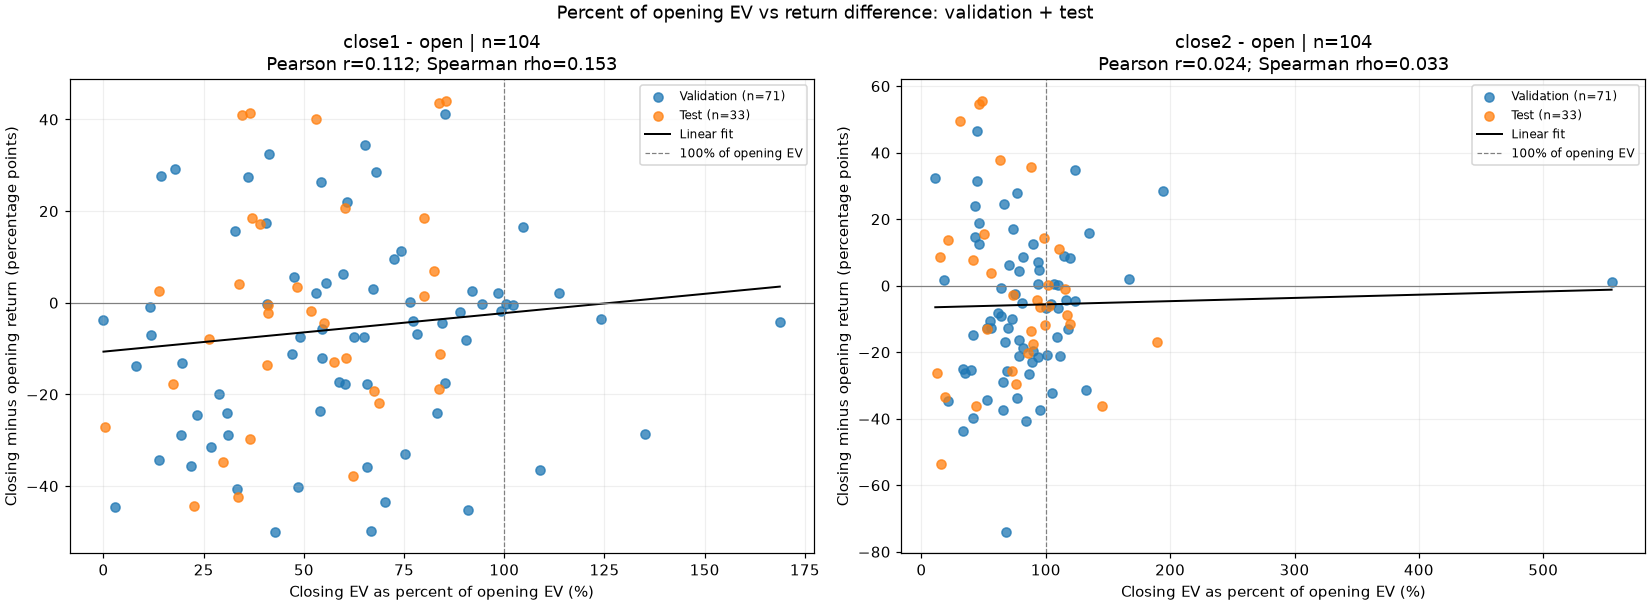

In [3]:
records=[]
for pair,sample in plot_pairs.groupby('pair',sort=False):
    for split,part in [('Combined',sample),*list(sample.groupby('split',sort=False))]:
        x,y=part.pct_of_open_ev,part.delta_return_pp
        records.append(dict(pair=pair,split=split,events=len(part),Pearson_r=pearsonr(x,y).statistic,
            Spearman_rho=spearmanr(x,y).statistic,mean_pct_of_open_ev=x.mean(),mean_return_difference_pp=y.mean()))
correlations=add_pearson_intervals(pd.DataFrame(records))
print(correlations.round(4).to_string(index=False))

def scatter(ax,part,title):
    for split,color in [('Validation','tab:blue'),('Test','tab:orange')]:
        g=part.loc[part.split.eq(split)]
        if len(g):ax.scatter(g.pct_of_open_ev,g.delta_return_pp,color=color,alpha=.75,label=f'{split} (n={len(g)})')
    x,y=part.pct_of_open_ev,part.delta_return_pp
    grid=np.linspace(x.min(),x.max(),100)
    ax.plot(grid,np.polyval(np.polyfit(x,y,1),grid),color='black',lw=1.3,label='Linear fit')
    ax.axhline(0,color='gray',lw=.8);ax.axvline(100,color='gray',lw=.8,ls='--',label='100% of opening EV')
    ax.set(title=f'{title} | n={len(part)}\nPearson r={pearsonr(x,y).statistic:.3f}; Spearman rho={spearmanr(x,y).statistic:.3f}',
        xlabel='Closing EV as percent of opening EV (%)',ylabel='Closing minus opening return (percentage points)')
    ax.legend(fontsize=8);ax.grid(alpha=.2)
fig,axes=plt.subplots(1,2,figsize=(15,5.5),constrained_layout=True)
for ax,(pair,part) in zip(axes,plot_pairs.groupby('pair',sort=False)):scatter(ax,part,pair)
fig.suptitle('Percent of opening EV vs return difference: validation + test')
plt.show()


## Validation and test separately

Same unfiltered events, separated to expose period differences across the model refit.


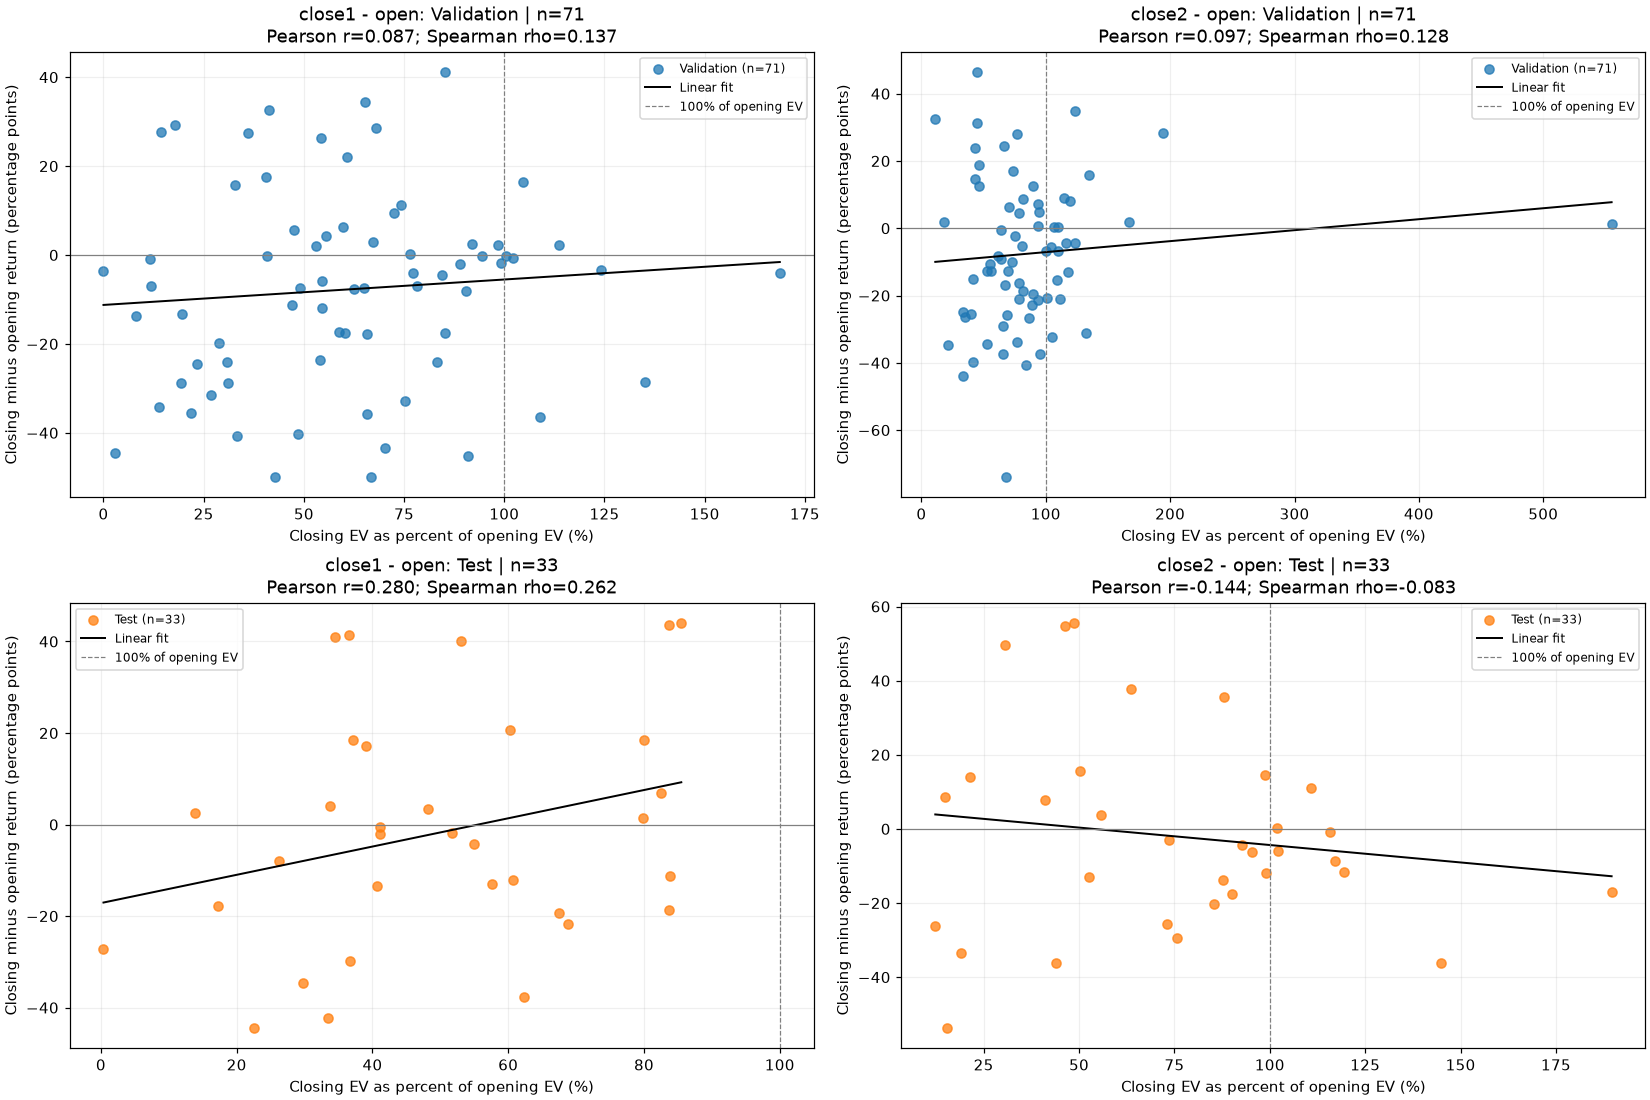

In [4]:
fig,axes=plt.subplots(2,2,figsize=(15,10),constrained_layout=True)
for col,(pair,sample) in enumerate(plot_pairs.groupby('pair',sort=False)):
    for row,split in enumerate(['Validation','Test']):scatter(axes[row,col],sample.loc[sample.split.eq(split)],f'{pair}: {split}')
plt.show()


## Closing EV at most 100% of opening EV

Keep only finite EV ratios **<= 100%**, inclusive, separately for close1/open and close2/open. The x-axis remains closing EV as a percentage of opening EV; the y-axis remains closing minus opening realized return in percentage points. No lower cutoff is applied. Events with zero opening EV remain excluded because their ratios are undefined. The original plots above remain unfiltered by this cutoff.

Counts and descriptive correlations are recomputed on the retained events. Both pooled and separate validation/test plots are shown.


Filter: closing EV <= 100% of opening EV
                          finite_ratio_events  retained_events  excluded_above_100
pair          split                                                               
close1 - open Validation                   71               63                   8
close2 - open Validation                   71               52                  19
close1 - open Test                         33               33                   0
close2 - open Test                         33               25                   8
         pair      split  events  Pearson_r  Pearson_CI95_low  Pearson_CI95_high  Spearman_rho  mean_pct_of_open_ev  mean_return_difference_pp  bootstrap_valid_draws
close1 - open   Combined      96     0.1638            0.0198             0.3011        0.1750              52.0699                    -5.7673                  10000
close1 - open Validation      63     0.1214           -0.0810             0.3081        0.1458              53.1824              

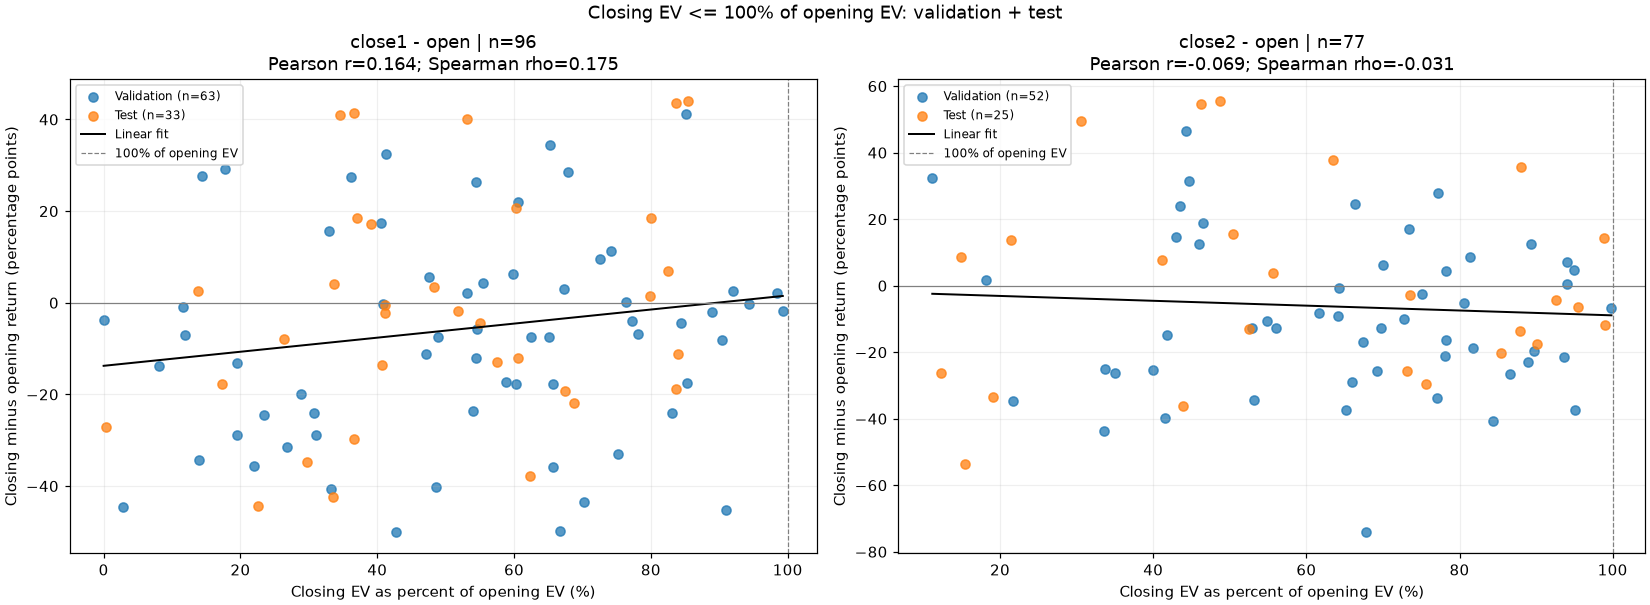

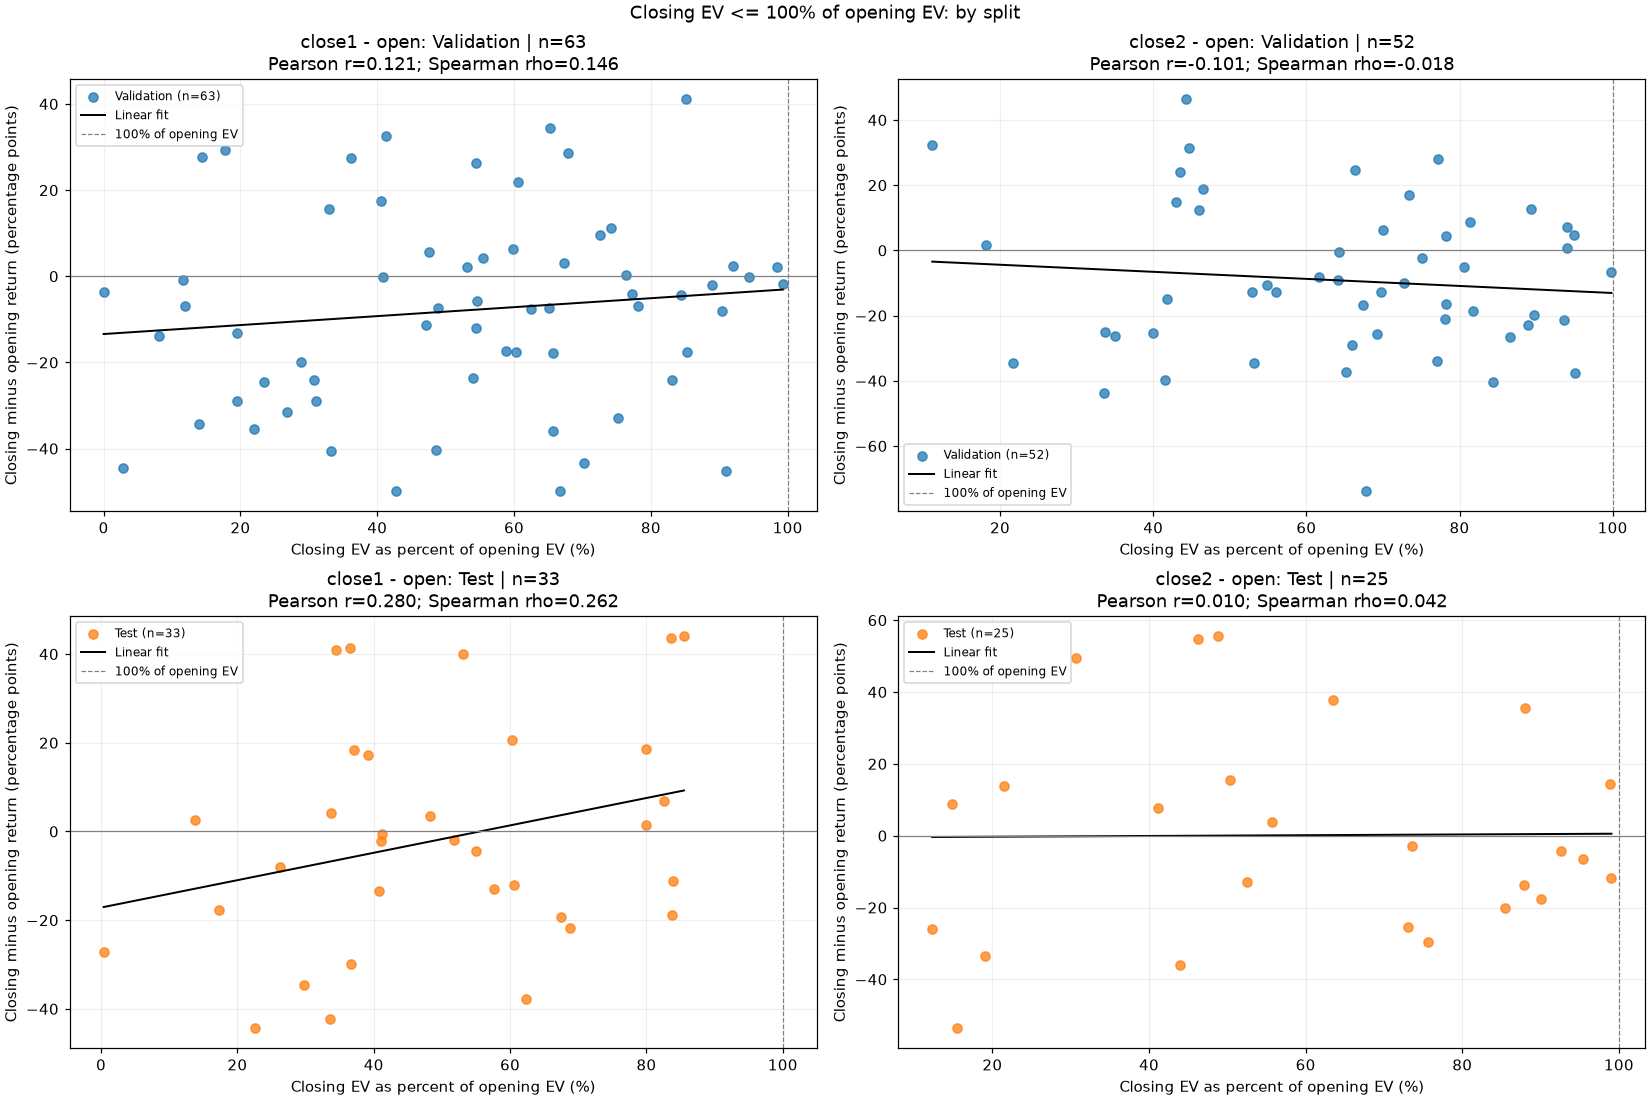

In [5]:
filtered_pairs = plot_pairs.loc[plot_pairs.pct_of_open_ev.le(100)].copy()
filter_counts = plot_pairs.groupby(['pair','split'], sort=False).size().rename('finite_ratio_events').to_frame()
filter_counts['retained_events'] = filtered_pairs.groupby(['pair','split']).size().reindex(filter_counts.index, fill_value=0)
filter_counts['excluded_above_100'] = filter_counts.finite_ratio_events - filter_counts.retained_events
print('Filter: closing EV <= 100% of opening EV')
print(filter_counts.to_string())
filtered_records = []
for pair, sample in filtered_pairs.groupby('pair', sort=False):
    for split, part in [('Combined',sample), *list(sample.groupby('split',sort=False))]:
        x,y = part.pct_of_open_ev, part.delta_return_pp
        valid_corr = len(part) >= 2 and x.nunique() > 1 and y.nunique() > 1
        filtered_records.append(dict(pair=pair, split=split, events=len(part),
            Pearson_r=pearsonr(x,y).statistic if valid_corr else np.nan,
            Spearman_rho=spearmanr(x,y).statistic if valid_corr else np.nan,
            mean_pct_of_open_ev=x.mean(), mean_return_difference_pp=y.mean()))
filtered_correlations = add_pearson_intervals(pd.DataFrame(filtered_records), filtered=True)
print(filtered_correlations.round(4).to_string(index=False))
assert filtered_pairs.pct_of_open_ev.le(100).all()
fig,axes = plt.subplots(1,2,figsize=(15,5.5),constrained_layout=True)
for ax,pair in zip(axes, plot_pairs['pair'].drop_duplicates()):
    part = filtered_pairs.loc[filtered_pairs.pair.eq(pair)]
    if len(part) >= 2 and part.pct_of_open_ev.nunique() > 1:
        scatter(ax,part,pair)
    else:
        ax.set_title(f'{pair}: insufficient retained events')
fig.suptitle('Closing EV <= 100% of opening EV: validation + test')
plt.show()

fig,axes = plt.subplots(2,2,figsize=(15,10),constrained_layout=True)
for col,pair in enumerate(plot_pairs['pair'].drop_duplicates()):
    for row,split in enumerate(['Validation','Test']):
        part = filtered_pairs.loc[filtered_pairs.pair.eq(pair) & filtered_pairs.split.eq(split)]
        if len(part) >= 2 and part.pct_of_open_ev.nunique() > 1:
            scatter(axes[row,col],part,f'{pair}: {split}')
        else:
            axes[row,col].set_title(f'{pair}: {split}, insufficient retained events')
fig.suptitle('Closing EV <= 100% of opening EV: by split')
plt.show()
